# Task 2 — MobileNet Baseline (frozen transfer learning)

**Goal:** a first, reproducible baseline for the document photo **quality gate** (good / bad) of the Telegram bot.

- **Main model:** **MobileNetV3-Small**, the first model selected in the Task 1 memo (section 8: MobileNetV3-Small, EfficientNet-B0, YOLOv8n-cls).
- **Course reference:** **MobileNetV2**, trained with exactly the same pipeline, because the task description names it as the baseline.
- Both use an ImageNet-pretrained, **frozen** backbone with the standard head: global average pooling → dense → dropout → single sigmoid output.

| | |
|---|---|
| Dataset | `5_practice/data/quality_dataset` (1800 synthetic images: INN, SNILS, passport) |
| Split | 70 / 15 / 15 by source document, stratified by document class: `6_practice/common/split_70_15_15.jsonl` |
| Positive class | **bad** (label 1); good = 0 |
| Seed | **24500003** (student ID) |
| Hardware | i7-10750H CPU (training and latency on CPU) |

The test split is used **only once**, in the evaluation section. Early stopping uses validation only, and the decision threshold is fixed at 0.5 (it is not tuned).

In [1]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision import models
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "common"))
import quality_common as qc

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---- all hyperparameters in one place (logged with the results) ----
HP = {
    "seed": qc.SEED,
    "image_size": 224,
    "normalization": "ImageNet mean/std",
    "batch_size": 32,
    "optimizer": "Adam",
    "learning_rate": 1e-3,
    "max_epochs": 30,
    "early_stopping": "val_loss, patience 5, best weights restored",
    "head": "GAP -> Linear(C,128) -> ReLU -> Dropout(0.3) -> Linear(128,1) -> sigmoid",
    "dropout": 0.3,
    "hidden_units": 128,
    "loss": "BCEWithLogitsLoss",
    "train_augmentation": "random 0/90/180/270 rotation, both classes",
    "backbone": "ImageNet pretrained, frozen (BatchNorm in eval mode)",
    "threshold": 0.5,
}
print("device:", DEVICE, "| torch", torch.__version__)
print(json.dumps(HP, indent=2))

device: cpu | torch 2.14.1+cpu
{
  "seed": 24500003,
  "image_size": 224,
  "normalization": "ImageNet mean/std",
  "batch_size": 32,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "max_epochs": 30,
  "early_stopping": "val_loss, patience 5, best weights restored",
  "head": "GAP -> Linear(C,128) -> ReLU -> Dropout(0.3) -> Linear(128,1) -> sigmoid",
  "dropout": 0.3,
  "hidden_units": 128,
  "loss": "BCEWithLogitsLoss",
  "train_augmentation": "random 0/90/180/270 rotation, both classes",
  "backbone": "ImageNet pretrained, frozen (BatchNorm in eval mode)",
  "threshold": 0.5
}


## 1. Data: 70 / 15 / 15 split by source document

The Homework 3 split was random (73/12/15), so it is rebuilt here to be exactly **70/15/15 inside every document class**. The unit of the split is the **source document** (`source_id`): the good and bad variants of one document always end up in the same split, so the test set contains only documents the model has never seen.

In [2]:
qc.make_split()                    # deterministic with seed 24500003
splits = qc.load_split()
qc.check_split(splits)

train       1260 (70%)  good=630 bad=630  inn=420 passport=420 snils=420
validation   270 (15%)  good=135 bad=135  inn=90 passport=90 snils=90
test         270 (15%)  good=135 bad=135  inn=90 passport=90 snils=90
No source_id appears in two splits: OK


Images are decoded once: **RGB → resize 640→224 → uint8 cache**. Normalisation (ImageNet mean/std) is applied per batch. Binary labels: good = 0, bad = 1.

train      images (1260, 3, 224, 224)  labels (1260,)  bad share 0.50
validation images (270, 3, 224, 224)  labels (270,)  bad share 0.50
test       images (270, 3, 224, 224)  labels (270,)  bad share 0.50
loaded in 8.0 s


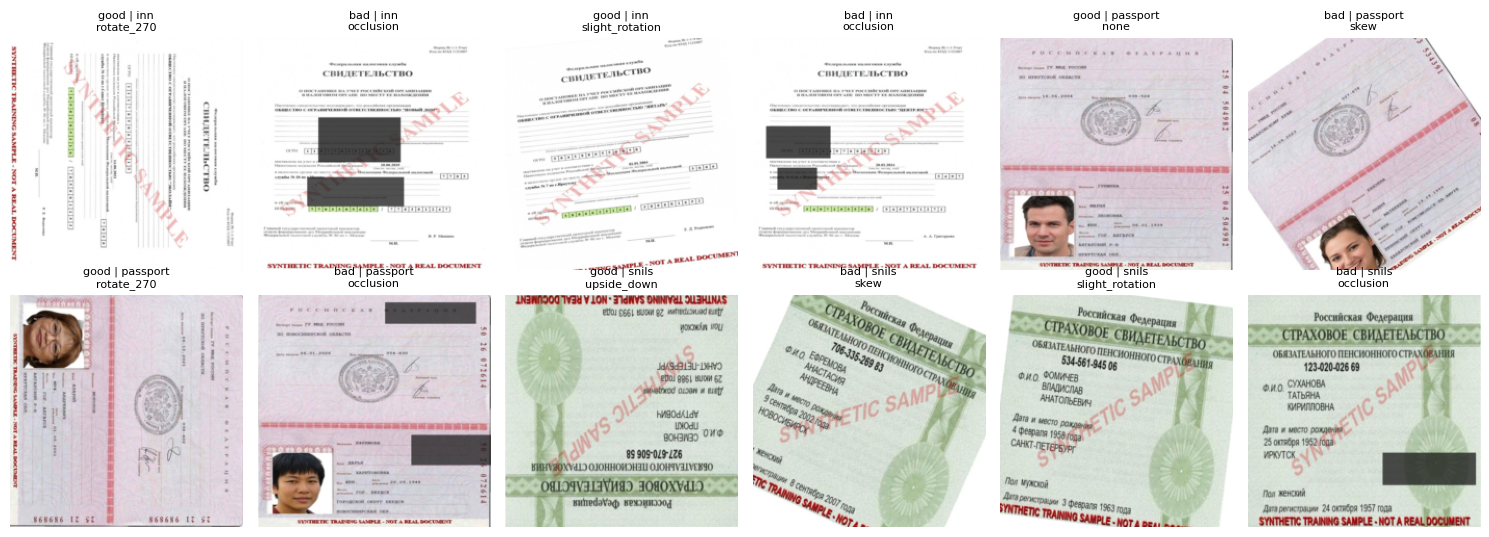

In [3]:
t0 = time.time()
data = {s: qc.load_images(splits[s], size=HP["image_size"]) for s in qc.SPLITS}
for s, (x, y) in data.items():
    print(f"{s:<10} images {tuple(x.shape)}  labels {tuple(y.shape)}  bad share {y.mean():.2f}")
print(f"loaded in {time.time() - t0:.1f} s")

# a few training examples
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for ax, i in zip(axes.flat, range(0, 1260, 105)):
    r = splits["train"][i]
    ax.imshow(data["train"][0][i].permute(1, 2, 0).numpy())
    ax.set_title(f"{r['quality_label']} | {r['class_name']}\n{r['defect_type'] if r['quality_label']=='bad' else r['good_augmentation'][:15]}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Model: pretrained frozen backbone + standard head

`requires_grad = False` for every backbone weight, and the backbone is kept in `eval()` mode, so its BatchNorm statistics stay as learned on ImageNet. Only the new head is trained.

In [4]:
BACKBONES = {
    # name: (constructor with ImageNet weights, number of output channels of .features)
    "mobilenet_v3_small": (lambda: models.mobilenet_v3_small(weights="IMAGENET1K_V1"), 576),
    "mobilenet_v2":       (lambda: models.mobilenet_v2(weights="IMAGENET1K_V1"), 1280),
}

class QualityNet(nn.Module):
    def __init__(self, arch):
        super().__init__()
        build, channels = BACKBONES[arch]
        self.backbone = build().features
        for p in self.backbone.parameters():
            p.requires_grad = False
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),          # global average pooling
            nn.Linear(channels, HP["hidden_units"]), nn.ReLU(),
            nn.Dropout(HP["dropout"]),
            nn.Linear(HP["hidden_units"], 1),               # single logit -> sigmoid = P(bad)
        )

    def forward(self, x):
        return self.head(self.backbone(x))

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()                                 # frozen BN statistics
        return self

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

for arch in BACKBONES:
    total, trainable = count_params(QualityNet(arch))
    print(f"{arch:<20} total {total:>9,}  trainable {trainable:>7,} ({trainable / total:.1%})")

mobilenet_v3_small   total 1,000,993  trainable  73,985 (7.4%)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\Vlad/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth


0.9%

1.8%

2.8%

3.7%

4.6%

... (101 outputs left out)

98.7%

99.6%

100.0%

mobilenet_v2         total 2,387,969  trainable 164,097 (6.9%)


## 3. Training loop

- Adam with lr 1e-3 and BCE loss on the logit.
- Random 90° rotations are applied to **both** classes during training. In the dataset only GOOD images are rotated, and this removes the shortcut "rotated = good" found in the Homework 3 audit.
- Early stopping on **validation** loss with patience 5; the best weights are restored.

In [5]:
def predict(model, x_uint8, batch_size=64):
    model.eval()
    probs = []
    with torch.inference_mode():
        for i in range(0, len(x_uint8), batch_size):
            xb = qc.imagenet_normalize(x_uint8[i:i + batch_size].to(DEVICE))
            probs.append(torch.sigmoid(model(xb)).squeeze(1).cpu())
    return torch.cat(probs).numpy()

def bce(y, p):
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def train_model(arch):
    qc.set_seed(HP["seed"])
    gen = torch.Generator().manual_seed(HP["seed"])
    model = QualityNet(arch).to(DEVICE)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=HP["learning_rate"])
    loss_fn = nn.BCEWithLogitsLoss()
    (x_tr, y_tr), (x_va, y_va) = data["train"], data["validation"]

    history, best, best_state, bad_epochs = [], float("inf"), None, 0
    t_start = time.time()
    for epoch in range(1, HP["max_epochs"] + 1):
        model.train()
        order = torch.randperm(len(x_tr), generator=gen)
        run_loss, run_correct = 0.0, 0
        for i in range(0, len(order), HP["batch_size"]):
            idx = order[i:i + HP["batch_size"]]
            xb = qc.imagenet_normalize(qc.random_rot90(x_tr[idx], gen).to(DEVICE))
            yb = y_tr[idx].to(DEVICE)
            logits = model(xb).squeeze(1)
            loss = loss_fn(logits, yb)
            opt.zero_grad(); loss.backward(); opt.step()
            run_loss += loss.item() * len(idx)
            run_correct += ((logits > 0).float() == yb).sum().item()

        p_va = predict(model, x_va)
        rec = {
            "epoch": epoch,
            "train_loss": run_loss / len(x_tr), "train_acc": run_correct / len(x_tr),
            "val_loss": bce(y_va.numpy(), p_va), "val_acc": float(((p_va >= 0.5) == y_va.numpy()).mean()),
        }
        history.append(rec)
        print(f"[{arch}] epoch {epoch:2d}  train loss {rec['train_loss']:.4f} acc {rec['train_acc']:.3f} | "
              f"val loss {rec['val_loss']:.4f} acc {rec['val_acc']:.3f}")

        if rec["val_loss"] < best - 1e-4:
            best, bad_epochs = rec["val_loss"], 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= 5:
                print(f"early stopping: no val_loss improvement for 5 epochs")
                break

    train_time = time.time() - t_start
    model.load_state_dict(best_state)
    best_epoch = min(history, key=lambda h: h["val_loss"])["epoch"]
    print(f"best epoch {best_epoch}, training time {train_time:.0f} s")
    return model, history, train_time, best_epoch

## 4. Train MobileNetV3-Small (main model)

[mobilenet_v3_small] epoch  1  train loss 0.5753 acc 0.728 | val loss 0.4359 acc 0.852


[mobilenet_v3_small] epoch  2  train loss 0.3824 acc 0.866 | val loss 0.2984 acc 0.863


[mobilenet_v3_small] epoch  3  train loss 0.2794 acc 0.906 | val loss 0.2389 acc 0.867


[mobilenet_v3_small] epoch  4  train loss 0.2082 acc 0.938 | val loss 0.1887 acc 0.948


[mobilenet_v3_small] epoch  5  train loss 0.1790 acc 0.940 | val loss 0.1806 acc 0.907


[mobilenet_v3_small] epoch  6  train loss 0.1609 acc 0.945 | val loss 0.1581 acc 0.948


... (20 outputs left out)

[mobilenet_v3_small] epoch 27  train loss 0.0581 acc 0.982 | val loss 0.0436 acc 0.981


[mobilenet_v3_small] epoch 28  train loss 0.0540 acc 0.979 | val loss 0.0402 acc 0.985


[mobilenet_v3_small] epoch 29  train loss 0.0628 acc 0.977 | val loss 0.0412 acc 0.996


[mobilenet_v3_small] epoch 30  train loss 0.0597 acc 0.983 | val loss 0.0584 acc 0.978
best epoch 26, training time 203 s


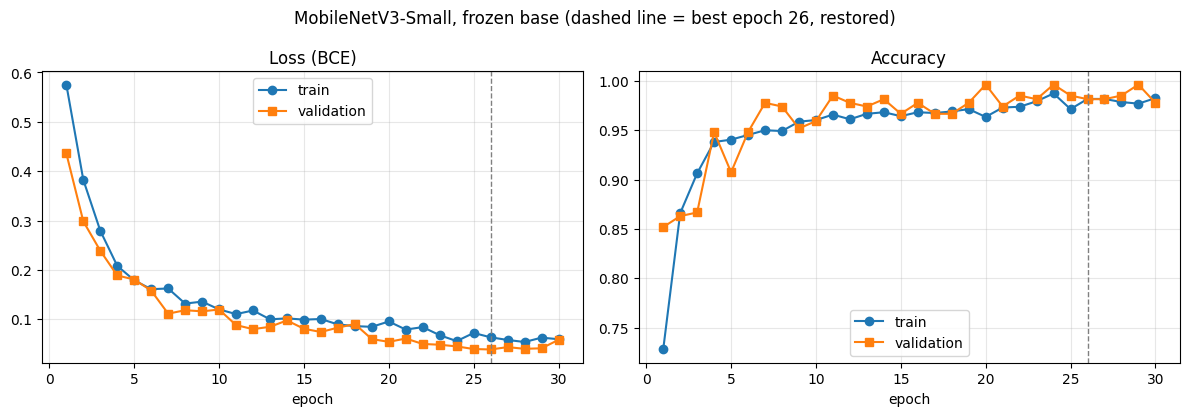

In [6]:
results = {}

def run(arch, title):
    model, history, train_time, best_epoch = train_model(arch)
    pd.DataFrame(history).to_csv(OUT / f"{arch}_history.csv", index=False)
    qc.plot_history(history, title, OUT / f"{arch}_curves.png"); plt.show()
    torch.save(model.state_dict(), OUT / f"{arch}_frozen.pt")
    results[arch] = {"model": model, "history": history, "train_time_s": train_time, "best_epoch": best_epoch}

run("mobilenet_v3_small", "MobileNetV3-Small, frozen base")

## 5. Train MobileNetV2 (course reference, identical pipeline)

[mobilenet_v2] epoch  1  train loss 0.5406 acc 0.744 | val loss 0.3657 acc 0.881


[mobilenet_v2] epoch  2  train loss 0.3036 acc 0.906 | val loss 0.2298 acc 0.944


[mobilenet_v2] epoch  3  train loss 0.2066 acc 0.940 | val loss 0.1906 acc 0.922


[mobilenet_v2] epoch  4  train loss 0.1529 acc 0.948 | val loss 0.1304 acc 0.963


[mobilenet_v2] epoch  5  train loss 0.1424 acc 0.953 | val loss 0.1147 acc 0.967


[mobilenet_v2] epoch  6  train loss 0.1343 acc 0.958 | val loss 0.0964 acc 0.974


... (18 outputs left out)

[mobilenet_v2] epoch 25  train loss 0.0776 acc 0.970 | val loss 0.0532 acc 0.981


[mobilenet_v2] epoch 26  train loss 0.0600 acc 0.983 | val loss 0.0494 acc 0.981


[mobilenet_v2] epoch 27  train loss 0.0599 acc 0.981 | val loss 0.0525 acc 0.981


[mobilenet_v2] epoch 28  train loss 0.0540 acc 0.979 | val loss 0.0917 acc 0.974
early stopping: no val_loss improvement for 5 epochs
best epoch 23, training time 983 s


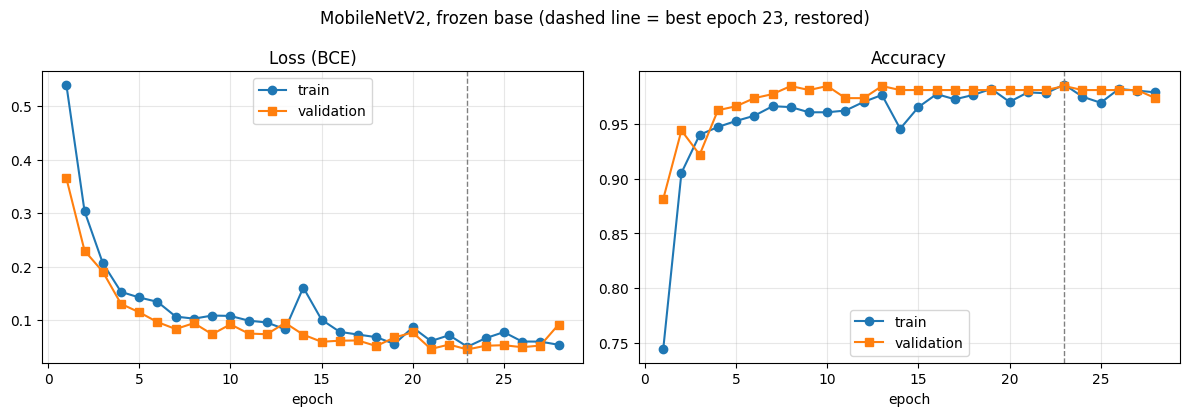

In [7]:
run("mobilenet_v2", "MobileNetV2, frozen base")

## 6. Evaluation on the test split (used once)

The test split was not used for training, early stopping or the threshold. Bad is the positive class.

In [8]:
x_te, y_te = data["test"]
rows, report = [], {}
for arch, res in results.items():
    model = res["model"]
    p_te = predict(model, x_te)
    m = qc.compute_metrics(y_te.numpy(), p_te, threshold=HP["threshold"])
    parts = qc.breakdown(splits["test"], p_te, threshold=HP["threshold"])
    lat_mean, lat_std = qc.cpu_latency_ms(model)
    size = qc.model_size_mb(model)
    total, trainable = count_params(model)
    checks = qc.acceptance_check(m, parts, lat_mean, size)
    report[arch] = {"metrics": m, "breakdown": parts, "cpu_latency_ms": [round(lat_mean, 1), round(lat_std, 1)],
                    "size_mb": round(size, 1), "params_total": total, "params_trainable": trainable,
                    "train_time_s": round(res["train_time_s"], 1), "best_epoch": res["best_epoch"],
                    "acceptance": checks}
    rows.append({"model": arch, "accuracy": m["accuracy"], "precision_bad": m["precision_bad"],
                 "recall_bad": m["recall_bad"], "f1_bad": m["f1_bad"], "f1_macro": m["f1_macro"],
                 "cpu_latency_ms": round(lat_mean, 1), "size_mb": round(size, 1),
                 "params_M": round(total / 1e6, 2), "train_time_s": round(res["train_time_s"]),
                 "best_epoch": res["best_epoch"]})
    res["p_test"] = p_te

summary = pd.DataFrame(rows).set_index("model")
summary.round(4)

,accuracy,precision_bad,recall_bad,f1_bad,f1_macro,cpu_latency_ms,size_mb,params_M,train_time_s,best_epoch
model,,,,,,,,,,
mobilenet_v3_small,0.9778,0.9924,0.9630,0.9774,0.9778,8.9,3.9,1.00,203,26
mobilenet_v2,0.9852,0.9852,0.9852,0.9852,0.9852,17.6,9.3,2.39,983,23


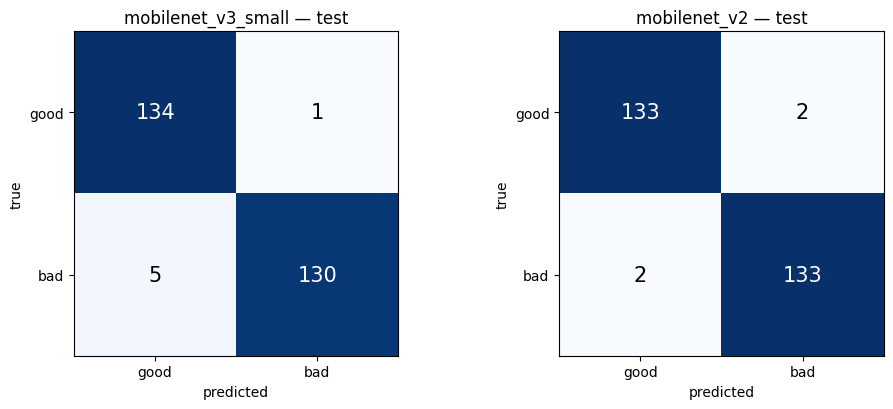

In [9]:
fig, axes = plt.subplots(1, len(report), figsize=(5 * len(report), 4.2))
for ax, (arch, rep) in zip(np.atleast_1d(axes), report.items()):
    cm = np.array(rep["metrics"]["confusion_matrix"])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=15,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["good", "bad"]); ax.set_yticks([0, 1], ["good", "bad"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{arch} — test")
    qc.plot_confusion(cm, f"{arch} — test", OUT / f"{arch}_confusion_matrix.png"); plt.close()
plt.tight_layout(); plt.show()

In [10]:
for arch, rep in report.items():
    print(f"===== {arch}")
    print("recall(bad) per defect:     ", rep["breakdown"]["recall_bad_per_defect"])
    print("accuracy(good) per aug:     ", rep["breakdown"]["accuracy_good_per_augmentation"])
    print("accuracy per document class:", rep["breakdown"]["accuracy_per_document_class"])
    print("acceptance criteria (Task 1 memo):")
    for name, ok in rep["acceptance"].items():
        print(f"   {'PASS' if ok else 'FAIL'}  {name}")

===== mobilenet_v3_small
recall(bad) per defect:      {'blur': 1.0, 'exposure': 0.9286, 'glare': 1.0, 'occlusion': 0.88, 'skew': 1.0}
accuracy(good) per aug:      {'none': 1.0, 'rotate_270': 0.9286, 'rotate_90': 1.0, 'slight_rotation': 1.0, 'upside_down': 1.0}
accuracy per document class: {'inn': 0.9889, 'passport': 0.9556, 'snils': 0.9889}
acceptance criteria (Task 1 memo):
   PASS  Q1 accuracy >= 0.92
   PASS  Q2 F1(bad) >= 0.92
   PASS  Q3 recall(bad) >= 0.93
   PASS  Q4 precision(bad) >= 0.88
   PASS  Q5 recall per defect >= 0.85
   PASS  C1 CPU latency <= 50 ms
   PASS  C2 size <= 25 MB
===== mobilenet_v2
recall(bad) per defect:      {'blur': 1.0, 'exposure': 1.0, 'glare': 0.963, 'occlusion': 0.96, 'skew': 1.0}
accuracy(good) per aug:      {'none': 1.0, 'rotate_270': 1.0, 'rotate_90': 1.0, 'slight_rotation': 0.9512, 'upside_down': 1.0}
accuracy per document class: {'inn': 0.9778, 'passport': 0.9778, 'snils': 1.0}
acceptance criteria (Task 1 memo):
   PASS  Q1 accuracy >= 0.92
   P

## 7. Save results and the experiment log

In [11]:
(OUT / "test_metrics.json").write_text(json.dumps({"hyperparameters": HP, "results": report}, indent=2), encoding="utf-8")
summary.to_csv(OUT / "summary.csv")

log_path = Path.cwd().parent / "experiment_log.csv"
log = pd.DataFrame([{
    "date": time.strftime("%Y-%m-%d %H:%M"), "task": "task2", "model": arch, "regime": "frozen base",
    "seed": HP["seed"], "image_size": HP["image_size"], "batch_size": HP["batch_size"],
    "optimizer": HP["optimizer"], "lr": HP["learning_rate"], "epochs_run": len(results[arch]["history"]),
    "best_epoch": rep["best_epoch"], "train_time_s": rep["train_time_s"],
    "test_accuracy": round(rep["metrics"]["accuracy"], 4), "test_precision_bad": round(rep["metrics"]["precision_bad"], 4),
    "test_recall_bad": round(rep["metrics"]["recall_bad"], 4), "test_f1_bad": round(rep["metrics"]["f1_bad"], 4),
    "cpu_latency_ms": rep["cpu_latency_ms"][0], "size_mb": rep["size_mb"],
} for arch, rep in report.items()])
if log_path.exists():
    old = pd.read_csv(log_path)
    log = pd.concat([old[old["task"] != "task2"], log], ignore_index=True)
log.to_csv(log_path, index=False)
print("saved:", sorted(p.name for p in OUT.iterdir()))
log

saved: ['mobilenet_v2_confusion_matrix.png', 'mobilenet_v2_curves.png', 'mobilenet_v2_frozen.pt', 'mobilenet_v2_history.csv', 'mobilenet_v3_small_confusion_matrix.png', 'mobilenet_v3_small_curves.png', 'mobilenet_v3_small_frozen.pt', 'mobilenet_v3_small_history.csv', 'summary.csv', 'test_metrics.json']


,date,task,model,regime,seed,image_size,batch_size,optimizer,lr,epochs_run,best_epoch,train_time_s,test_accuracy,test_precision_bad,test_recall_bad,test_f1_bad,cpu_latency_ms,size_mb
0,2026-11-02 15:24,task2,mobilenet_v3_small,frozen base,24500003,224,32,Adam,0.001,30,26,202.9,0.9778,0.9924,0.9630,0.9774,8.9,3.9
1,2026-11-02 15:24,task2,mobilenet_v2,frozen base,24500003,224,32,Adam,0.001,28,23,983.0,0.9852,0.9852,0.9852,0.9852,17.6,9.3


## 8. Interpretation

**Test results (270 images, bad = positive class, threshold 0.5):**

| Model | Accuracy | Precision (bad) | Recall (bad) | F1 (bad) | Confusion [[TN, FP], [FN, TP]] | CPU latency | Size | Train time |
|---|---|---|---|---|---|---|---|---|
| **MobileNetV3-Small** | 0.978 | 0.992 | 0.963 | 0.977 | [[134, 1], [5, 130]] | **8.9 ms** | **3.9 MB** | 203 s |
| MobileNetV2 (reference) | 0.985 | 0.985 | 0.985 | 0.985 | [[133, 2], [2, 133]] | 17.6 ms | 9.3 MB | 983 s |

**Curves (training dynamics).**
- **No overfitting.** For both models train and validation loss go down together for ~25 epochs, and validation loss stays *below* training loss the whole time. This is expected: dropout (0.3) and the random 90° rotations are active only during training, so the training batches are harder than the clean validation images. There is no point where validation loss starts rising while training loss keeps falling, which would be the overfitting signature.
- **No underfitting.** Training accuracy reaches ~0.98 and validation accuracy ~0.98–0.99. The frozen ImageNet features are already enough to separate the five defects from clean photos.
- **Noisy validation curve.** Validation accuracy jumps by ±2–3 % between epochs because the set is small (270 images: one image = 0.37 %). The best epoch was chosen by validation **loss** (V3-Small: 26, V2: 23) and those weights were restored.
- **Head not saturated.** In the last epochs the curves flatten but are still slowly improving. Only the head is trained (74 k parameters for V3-Small, 164 k for V2), so the model has limited capacity. This is the expected ceiling of the frozen regime; fine-tuning the last blocks with a low LR is the next step.

**Errors.**
- **MobileNetV3-Small** misses 5 bad images: occlusion recall 0.88, exposure 0.93. These are the defects that cover only part of the page or change it globally without destroying edges. It raised only 1 false alarm on 135 good images (precision 0.99): when it says "retake the photo", it is almost always right.
- **MobileNetV2** is more balanced: 2 misses and 2 false alarms, with glare 0.96 and occlusion 0.96 as its weakest defects.
- **Rotation shortcut.** No sign of it: rotated GOOD images (90/180/270°) are classified correctly at 0.93–1.0, thanks to the rotation augmentation applied to both classes.

**Acceptance criteria from the Task 1 memo.** Both models pass all of them: accuracy and F1 ≥ 0.92, recall(bad) ≥ 0.93, precision(bad) ≥ 0.88, every defect ≥ 0.85, latency ≤ 50 ms, size ≤ 25 MB.

**Conclusion.**
- MobileNetV2 is ~0.7 pp more accurate (2 more correct images out of 270, within the noise of a 270-image test set).
- MobileNetV3-Small is **2× faster, 2.4× smaller and trained 5× faster**.
- For the first gate of the bot, speed and size matter and both models pass the quality bar, so **MobileNetV3-Small is kept as the baseline** to compare with YOLOv8n-cls and EfficientNet-B0. Its weakest point (occlusion recall 0.88) will be tracked in the next tasks.
- Remember that the thresholds include a margin for the 3–6 % synthetic-to-real gap: ~0.98 on synthetic data means an expected ~0.92–0.95 on real photos.
